In [2]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/features/customer_features.csv")

df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,AverageSpendPerOrder,EngagementScore,LoyaltyLevel,HighValueCustomer,CustomerActivity,CashbackPerOrder
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93,79.965,5.0,New,0,2.0,79.965
1,50002,1,9.0,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90,60.450,4.0,Regular,0,1.0,60.450
2,50003,1,9.0,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28,60.140,3.0,Regular,0,1.0,60.140
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07,67.035,3.0,New,0,1.0,67.035
4,50005,1,0.0,Phone,1,12.0,CC,Male,3.0,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60,64.800,5.0,New,0,2.0,64.800


In [3]:
##features for clustering
features = df.drop(columns=[
    "CustomerID",
    "Churn"
])

features.head()

,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,AverageSpendPerOrder,EngagementScore,LoyaltyLevel,HighValueCustomer,CustomerActivity,CashbackPerOrder
0,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93,79.965,5.0,New,0,2.0,79.965
1,9.0,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90,60.450,4.0,Regular,0,1.0,60.450
2,9.0,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28,60.140,3.0,Regular,0,1.0,60.140
3,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07,67.035,3.0,New,0,1.0,67.035
4,0.0,Phone,1,12.0,CC,Male,3.0,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60,64.800,5.0,New,0,2.0,64.800


In [4]:
##encode categorical features
features = pd.get_dummies(
    features,
    drop_first=True
)

features.head()

,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,AverageSpendPerOrder,EngagementScore,HighValueCustomer,CustomerActivity,CashbackPerOrder,PreferredLoginDevice_Mobile Phone,PreferredLoginDevice_Phone,PreferredPaymentMode_COD,PreferredPaymentMode_Cash on Delivery,PreferredPaymentMode_Credit Card,PreferredPaymentMode_Debit Card,PreferredPaymentMode_E wallet,PreferredPaymentMode_UPI,Gender_Male,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Mobile Phone,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single,LoyaltyLevel_New,LoyaltyLevel_Regular,LoyaltyLevel_VIP
0,4.0,3,6.0,3.0,3,2,9,1,11.0,1.0,1.0,5.0,159.93,79.965,5.0,0,2.0,79.965,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True,True,False,False
1,9.0,1,8.0,3.0,4,3,7,1,15.0,0.0,1.0,0.0,120.90,60.450,4.0,0,1.0,60.450,False,True,False,False,False,False,False,True,True,False,False,True,False,False,False,True,False,True,False
2,9.0,1,30.0,2.0,4,3,6,1,14.0,0.0,1.0,3.0,120.28,60.140,3.0,0,1.0,60.140,False,True,False,False,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False
3,0.0,3,15.0,2.0,4,5,8,0,23.0,0.0,1.0,3.0,134.07,67.035,3.0,0,1.0,67.035,False,True,False,False,False,True,False,False,True,False,True,False,False,False,False,True,True,False,False
4,0.0,1,12.0,3.0,3,5,3,0,11.0,1.0,1.0,3.0,129.60,64.800,5.0,0,2.0,64.800,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,True,True,False,False


In [5]:
##scale features
scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

scaled_features[:5]

array([[-0.73398944,  1.46977096, -1.14637901,  0.09265391, -0.67290016,
        -0.77299241,  1.85261649,  1.58429008, -1.30184921, -0.38594004,
        -0.68142312,  0.15143648, -0.35146531,  0.92578332, -0.5843689 ,
        -1.        , -0.62116544,  0.92578332,  1.01792257, -0.52899558,
        -0.26329781, -0.1648782 , -0.6029314 ,  1.19708664, -0.34986897,
        -0.28172889, -1.22746835, -0.28025713,  1.32149214, -0.40964315,
        -0.53998207, -0.22180771, -1.06270855,  1.46107627,  1.27224394,
        -0.62569783, -0.28720052],
       [-0.13570356, -0.71528595, -0.90672086,  0.09265391,  0.3037505 ,
        -0.04839247,  1.07842975,  1.58429008, -0.1878723 , -0.92430535,
        -0.68142312, -1.24900275, -1.14471501,  0.13056815, -0.80798047,
        -1.        , -0.85305732,  0.13056815, -0.98239299,  1.89037495,
        -0.26329781, -0.1648782 , -0.6029314 , -0.83536142, -0.34986897,
         3.54951177,  0.81468496, -0.28025713, -0.75672036,  2.44114909,
        -0.53998

In [6]:
##elbow method
inertia = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_features)

    inertia.append(model.inertia_)

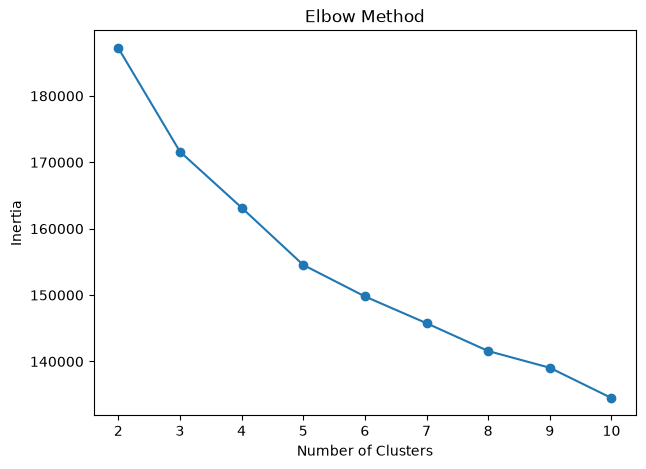

In [7]:
plt.figure(figsize=(7,5))

plt.plot(
    range(2,11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()


In [8]:
##silhouette score
scores = {}

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels
    )

    scores[k] = score

scores

{2: 0.15827725958205427,
 3: 0.09841843540892826,
 4: 0.09015398723647042,
 5: 0.10189217993979817,
 6: 0.10262439394537012,
 7: 0.10094022788522976,
 8: 0.10520117555544496,
 9: 0.10689938381605663,
 10: 0.10979294063721651}

In [9]:
##choosing best K
model = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = model.fit_predict(scaled_features)

In [10]:
##cluster size
df["Cluster"].value_counts().sort_index()

Cluster
0    1211
1     840
2     837
3     627
4    2115
Name: count, dtype: int64

In [11]:
##cluster profile
cluster_profile = df.groupby("Cluster").mean(numeric_only=True)

cluster_profile

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,AverageSpendPerOrder,EngagementScore,HighValueCustomer,CustomerActivity,CashbackPerOrder
Cluster,,,,,,,,,,,,,,,,,,,,
0,53674.885219,0.271676,6.369942,1.341866,15.343518,3.233691,4.020644,3.068538,4.027250,0.292320,16.224608,1.475640,2.159372,3.080099,148.525706,49.795997,6.868704,0.079273,3.635012,49.795997
1,52982.744048,0.151190,11.950000,1.758333,15.402381,3.010714,3.783333,3.101190,3.897619,0.272619,15.607143,4.565476,8.708333,7.702381,199.876012,22.014358,16.284524,0.733333,13.273810,22.014358
2,51412.909200,0.260454,6.630824,1.369176,14.617682,2.591398,3.151732,3.057348,3.274791,0.285544,15.318996,0.704898,1.464755,2.313023,127.144528,56.873062,4.761051,0.000000,2.169654,56.873062
3,52811.342903,0.036683,21.755981,1.529506,15.342903,2.834131,3.606061,2.953748,5.108453,0.291866,15.334928,1.601276,2.416268,5.814992,267.790957,89.250027,6.851675,1.000000,4.017544,89.250027
4,52813.313002,0.118676,9.509220,1.942790,16.201891,2.898818,3.698818,3.089362,4.553191,0.283215,15.627896,1.158392,1.893144,4.408511,177.626610,66.163715,5.950355,0.697872,3.051537,66.163715


In [14]:
##assigning business names
cluster_names = {
    0: "At-Risk Customers",
    1: "Loyal Customers",
    2: "Low Engagement Customers",
    3: "VIP Customers",
    4: "Regular Customers"
}

df["BehaviorSegment"] = df["Cluster"].map(cluster_names)

##segment check
df["BehaviorSegment"].value_counts()

BehaviorSegment
Regular Customers           2115
At-Risk Customers           1211
Loyal Customers              840
Low Engagement Customers     837
VIP Customers                627
Name: count, dtype: int64

In [ ]:
df.to_csv(
    "../data/features/customer_segments.csv",
    index=False
)

print("Customer segmentation dataset saved successfully!")